In [173]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder, OneHotEncoder
from imblearn.over_sampling import SMOTE

In [174]:
file_path = "D:/ict AI ML/Adult_DatasetCase_Study/adult_dataset.csv"

adult_df = pd.read_csv(file_path)

In [175]:
adult_df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [176]:
print("Dataset Shape:", adult_df.shape)
print("\nColumn Names:")
print(adult_df.columns.tolist())

print("\nData Types:")
print(adult_df.dtypes)

print("\nUnique Values:")
for col in adult_df.columns:
    print(f"\n{col}:")
    print(adult_df[col].unique()[:20])

Dataset Shape: (48842, 15)

Column Names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Data Types:
age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object

Unique Values:

age:
[39. 50. 38. 53. 28. 37. 49. 52. 31. 42. 30. 23. 32. 40. 34. 25. nan 54.
 35. 43.]

workclass:
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 '?' 'Self-emp-inc' 'Without-pay' 'Never-worked']

fnlwgt:
[ 77516  83311 215646 234721 338409 284582 160187 209642  45781 159449
 280464 141297 12227

### Initial Inspection — WHY

I inspected the data types and actual unique values before preprocessing because some missing values may be represented by special values such as `?`, which are not detected by `isnull()`.

##EDA

In [177]:
print(adult_df.describe())

                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  46400.000000  4.884200e+04   48842.000000  48842.000000  48842.000000   
mean      38.679116  1.896641e+05      10.078089   1079.067626     87.502314   
std       13.952954  1.056040e+05       2.570973   7452.019058    403.004552   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175505e+05       9.000000      0.000000      0.000000   
50%       37.000000  1.781445e+05      10.000000      0.000000      0.000000   
75%       48.000000  2.376420e+05      12.000000      0.000000      0.000000   
max      255.000000  1.490400e+06      16.000000  99999.000000   4356.000000   

       hours-per-week  
count    46400.000000  
mean        40.448599  
std         12.646992  
min          1.000000  
25%         40.000000  
50%         40.000000  
75%         45.000000  
max        250.000000  


In [178]:
print(adult_df.shape)

(48842, 15)


In [179]:
print(adult_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB
None


In [180]:
print("Missing values detected by isnull():")
print(adult_df.isnull().sum())

print("\n '?' values in each column:")
for col in adult_df.columns:
    count = (adult_df[col] == "?").sum() if adult_df[col].dtype == "object" else 0
    if count > 0:
        print(f"{col}: {count}")

Missing values detected by isnull():
age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64

 '?' values in each column:
workclass: 1763
occupation: 1758
native-country: 555


### Hidden Missing Values 

The value `?` represents missing information in categorical columns, so I will convert it to `NaN` before imputation instead of treating `?` as a genuine category.

In [181]:
adult_df = adult_df.replace("?", np.nan)

print("Missing values after converting '?' to NaN:")
print(adult_df.isnull().sum())

Missing values after converting '?' to NaN:
age               2442
workclass         5125
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    3260
income               0
dtype: int64


### Missing Value Conversion 

I converted `?` to `NaN` so that missing-value imputation methods can correctly identify and handle these observations.

##Drop Duplicates

In [182]:
print(adult_df.duplicated().sum())

16


In [183]:
adult_df.drop_duplicates(inplace=True)

In [184]:
print(adult_df.duplicated().sum())

0


### Duplicate Removal

I removed exact duplicate rows because they represent repeated observations and could give those observations unnecessary additional weight during model training.

##Spliting the data

In [185]:
X = adult_df.drop("income", axis=1)
y = adult_df["income"]

In [186]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)

In [187]:
num_cols = X_train.select_dtypes(include=["number"]).columns
cat_cols = X_train.select_dtypes(include=["object"]).columns

### Train-Test Split 

I split the data before fitting any preprocessing technique so that information from the test set does not leak into the training process.

##Numerical Data Preprocessing

###Handling Missing Value

In [188]:
print(X_train[num_cols].isna().sum())

age               1941
fnlwgt               0
education-num        0
capital-gain         0
capital-loss         0
hours-per-week    1960
dtype: int64


In [189]:
print(X_test[num_cols].isna().sum())

age               501
fnlwgt              0
education-num       0
capital-gain        0
capital-loss        0
hours-per-week    482
dtype: int64


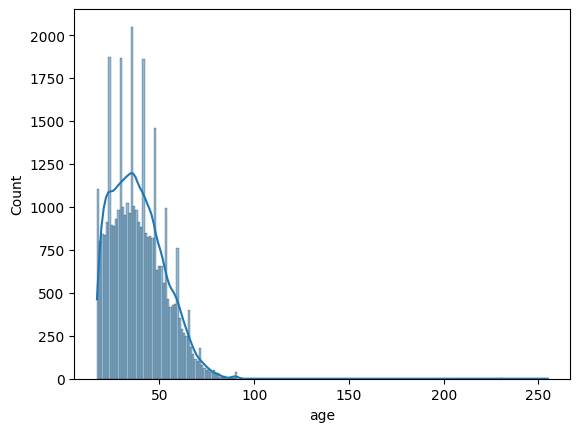

In [190]:
sns.histplot(data=X_train, x=X_train["age"], kde=True)
plt.show()

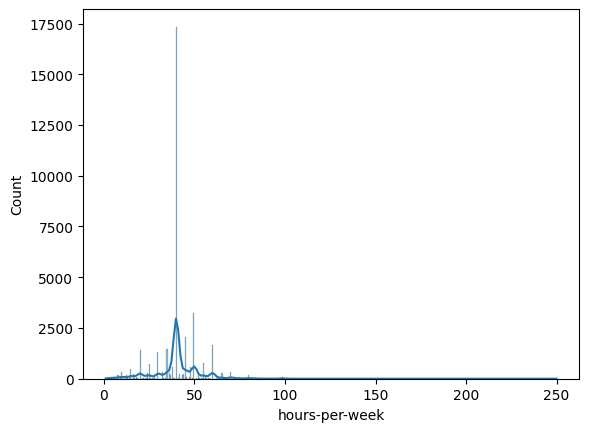

In [191]:
sns.histplot(data=X_train, x=X_train["hours-per-week"], kde=True)
plt.show()

In [192]:
num_imputer = SimpleImputer(strategy="median")

X_train_num = num_imputer.fit_transform(X_train[num_cols])
X_test_num = num_imputer.transform(X_test[num_cols])

###Outliers Handling

In [193]:
X_train_num = pd.DataFrame(
    X_train_num,
    columns=num_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    X_test_num,
    columns=num_cols,
    index=X_test.index
)

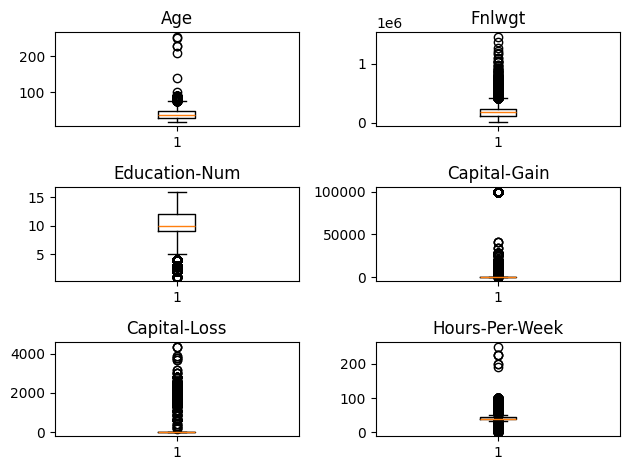

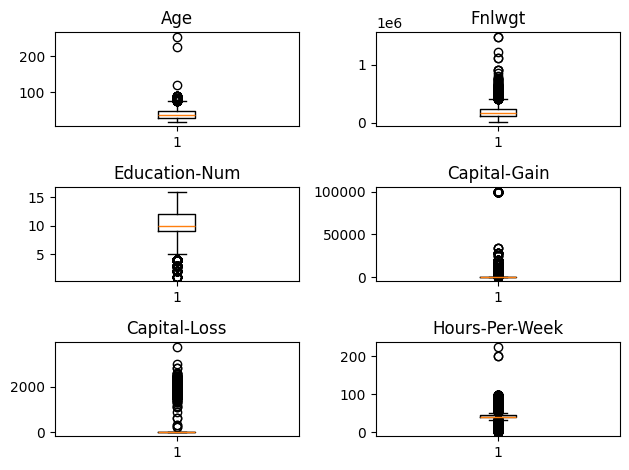

In [194]:
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    plt.boxplot(X_train_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    plt.boxplot(X_test_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()


In [195]:
Q1_train = X_train_num[num_cols].quantile(0.25)
Q3_train = X_train_num[num_cols].quantile(0.75)

IQR_train = Q3_train - Q1_train

lower_limit_train = Q1_train - 1.5 * IQR_train
upper_limit_train = Q3_train + 1.5 * IQR_train

outlier_counts = {}

for col in num_cols:
    outlier_count = (
        (X_train_num[col] < lower_limit_train[col]) |
        (X_train_num[col] > upper_limit_train[col])
    ).sum()

    outlier_counts[col] = outlier_count

outlier_summary = pd.DataFrame.from_dict(
    outlier_counts,
    orient="index",
    columns=["Outlier Count"]
)

print(outlier_summary)

                Outlier Count
age                       301
fnlwgt                   1176
education-num            1448
capital-gain             3229
capital-loss             1830
hours-per-week          10242


In [196]:
print("Extreme age values:")
display(
    X_train_num[
        (X_train_num["age"] < 18) |
        (X_train_num["age"] > 80)
    ]["age"].describe()
)

print("\nExtreme hours-per-week values:")
display(
    X_train_num[
        X_train_num["hours-per-week"] > 80
    ]["hours-per-week"].describe()
)

print("\nExtreme capital-gain values:")
display(
    X_train_num["capital-gain"].sort_values(ascending=False).head(20)
)

Extreme age values:


count    580.000000
mean      33.400000
std       33.997745
min       17.000000
25%       17.000000
50%       17.000000
75%       17.000000
max      255.000000
Name: age, dtype: float64


Extreme hours-per-week values:


count    241.000000
mean      96.215768
std       22.053229
min       81.000000
25%       85.000000
50%       96.000000
75%       99.000000
max      250.000000
Name: hours-per-week, dtype: float64


Extreme capital-gain values:


4389     99999.0
7090     99999.0
45611    99999.0
26593    99999.0
16422    99999.0
38241    99999.0
42975    99999.0
37343    99999.0
31972    99999.0
45600    99999.0
24638    99999.0
34998    99999.0
46573    99999.0
41215    99999.0
23999    99999.0
9184     99999.0
25841    99999.0
12533    99999.0
40415    99999.0
27413    99999.0
Name: capital-gain, dtype: float64

In [197]:
# Apply the limits calculated from training data to both datasets.

X_train_num = X_train_num.clip(
    lower=lower_limit_train,
    upper=upper_limit_train,
    axis=1
)

X_test_num = X_test_num.clip(
    lower=lower_limit_train,
    upper=upper_limit_train,
    axis=1
)

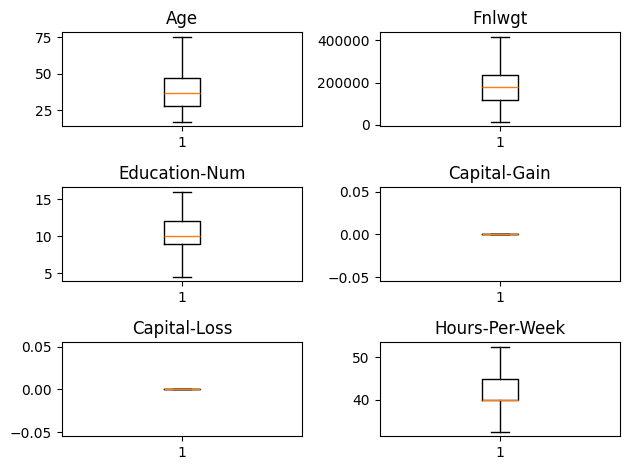

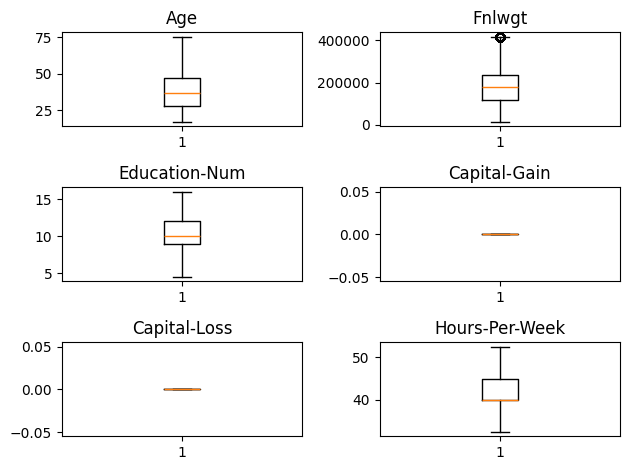

In [198]:
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    plt.boxplot(X_train_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()

for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 2, i)
    plt.boxplot(X_test_num[col])
    plt.title(col.replace("_", " ").title())
plt.tight_layout()
plt.show()


### Outlier Treatment — WHY

I used the IQR limits calculated from the training data to cap extreme values in both datasets. I did not calculate separate limits from the test set because doing so would allow test-set information to influence preprocessing.

###Standard Scaling

In [199]:
scalar = StandardScaler()
X_train_num_scale = scalar.fit_transform(X_train_num)
X_test_num_scale = scalar.transform(X_test_num)

### Standard Scaling — WHY

I used StandardScaler to place numerical features on a comparable scale by centering them around zero and scaling them according to their standard deviation.

##Categorical Data Preprocessing

###Handling null values

In [200]:
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

### Categorical Imputation — WHY

I used the most frequent category for missing categorical values. The imputer is fitted only on the training data and then applied to the test data to prevent data leakage.

###Converting all numpy arrays to Data Frames

In [201]:
X_train_num_scale = pd.DataFrame(
    X_train_num_scale,
    columns=num_cols,
    index=X_train.index
)

X_test_num_scale = pd.DataFrame(
    X_test_num_scale,
    columns=num_cols,
    index=X_test.index
)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=cat_cols,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=cat_cols,
    index=X_test.index
)

In [202]:
for col in cat_cols:
  print(f"{col}: {X_train_cat[col].unique()}")

workclass: ['Local-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'State-gov'
 'Self-emp-inc' 'Never-worked' 'Without-pay']
education: ['Assoc-acdm' 'Bachelors' 'Some-college' 'HS-grad' '9th' '7th-8th'
 'Assoc-voc' 'Masters' 'Preschool' '11th' '1st-4th' '5th-6th' '10th'
 'Doctorate' 'Prof-school' '12th']
marital-status: ['Divorced' 'Married-civ-spouse' 'Never-married' 'Widowed'
 'Married-AF-spouse' 'Married-spouse-absent' 'Separated']
occupation: ['Tech-support' 'Prof-specialty' 'Other-service' 'Sales'
 'Transport-moving' 'Adm-clerical' 'Craft-repair' 'Handlers-cleaners'
 'Farming-fishing' 'Machine-op-inspct' 'Exec-managerial' 'Protective-serv'
 'Priv-house-serv' 'Armed-Forces']
relationship: ['Not-in-family' 'Husband' 'Own-child' 'Unmarried' 'Wife' 'Other-relative']
race: ['Black' 'White' 'Amer-Indian-Eskimo' 'Asian-Pac-Islander' 'Other']
sex: ['Male' 'Female']
native-country: ['United-States' 'Mexico' 'Peru' 'Philippines' 'Columbia' 'Haiti' 'Cuba'
 'Germany' 'Japan' 'China' 'Jamaica

###Encoding

####Ordinal Encoding

In [203]:
ordinal_encoder = OrdinalEncoder(
    categories=[[
        'Preschool',
        '1st-4th',
        '5th-6th',
        '7th-8th',
        '9th',
        '10th',
        '11th',
        '12th',
        'HS-grad',
        'Some-college',
        'Assoc-voc',
        'Assoc-acdm',
        'Bachelors',
        'Masters',
        'Prof-school',
        'Doctorate'
    ]]
)

X_train_ordinal = ordinal_encoder.fit_transform(
    X_train_cat[['education']]
)

X_test_ordinal = ordinal_encoder.transform(
    X_test_cat[['education']]
)

####OneHot Encoding

In [204]:
col_one_hot = [col for col in cat_cols if col != "education"]

onehot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

X_train_onehot = onehot_encoder.fit_transform(
    X_train_cat[col_one_hot]
)

X_test_onehot = onehot_encoder.transform(
    X_test_cat[col_one_hot]
)

onehot_names = onehot_encoder.get_feature_names_out(col_one_hot)

X_train_onehot = pd.DataFrame(
    X_train_onehot,
    columns=onehot_names,
    index=X_train.index
)

X_test_onehot = pd.DataFrame(
    X_test_onehot,
    columns=onehot_names,
    index=X_test.index
)

In [205]:
X_test_onehot = pd.DataFrame(
    X_test_onehot,
    columns=onehot_names,
    index=X_test.index
)

In [206]:
# Combining Encoded Features

# Combine Ordinal Encoding and OneHot Encoding

X_train_ordinal = pd.DataFrame(
    X_train_ordinal,
    columns=['education'],
    index=X_train.index
)

X_test_ordinal = pd.DataFrame(
    X_test_ordinal,
    columns=['education'],
    index=X_test.index
)

X_train_encoded = pd.concat(
    [X_train_ordinal, X_train_onehot],
    axis=1
)

X_test_encoded = pd.concat(
    [X_test_ordinal, X_test_onehot],
    axis=1
)


#### Concatinating Onehot and ordinal

In [207]:
X_train_final = pd.concat(
    [X_train_num_scale, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num_scale, X_test_encoded],
    axis=1
)

####Concatinating encoding and numerical columns

In [208]:
X_train_final = pd.concat(
    [X_train_num_scale, X_train_encoded],
    axis=1
)

X_test_final = pd.concat(
    [X_test_num_scale, X_test_encoded],
    axis=1
)

In [209]:
print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (39060, 90)
Testing shape: (9766, 90)


####Label Encoding

In [210]:
adult_df["income"].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [211]:
label_mapping = {
    '<=50K': 0,
    '>50K': 1,
    '<=50K.': 0,
    '>50K.': 1
}

y_train = y_train.map(label_mapping)
y_test = y_test.map(label_mapping)

print("Training target values:")
print(y_train.value_counts())

print("\nTesting target values:")
print(y_test.value_counts())

Training target values:
income
0    29711
1     9349
Name: count, dtype: int64

Testing target values:
income
0    7428
1    2338
Name: count, dtype: int64


### Label Encoding — WHY

I encoded the binary income target as 0 and 1 because the target represents two classes: income at or below 50K and income above 50K.

###Inbalance

In [212]:
print(y_train.value_counts())

income
0    29711
1     9349
Name: count, dtype: int64


In [213]:
smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_final,
    y_train
)

### SMOTE — WHY

The training target is imbalanced, so I used SMOTE only on the training data to create synthetic minority-class observations. The test set remains unchanged so that model evaluation represents the original data distribution.

In [214]:
print(y_train_balanced.value_counts())

income
0    29711
1    29711
Name: count, dtype: int64


###Feature Selection

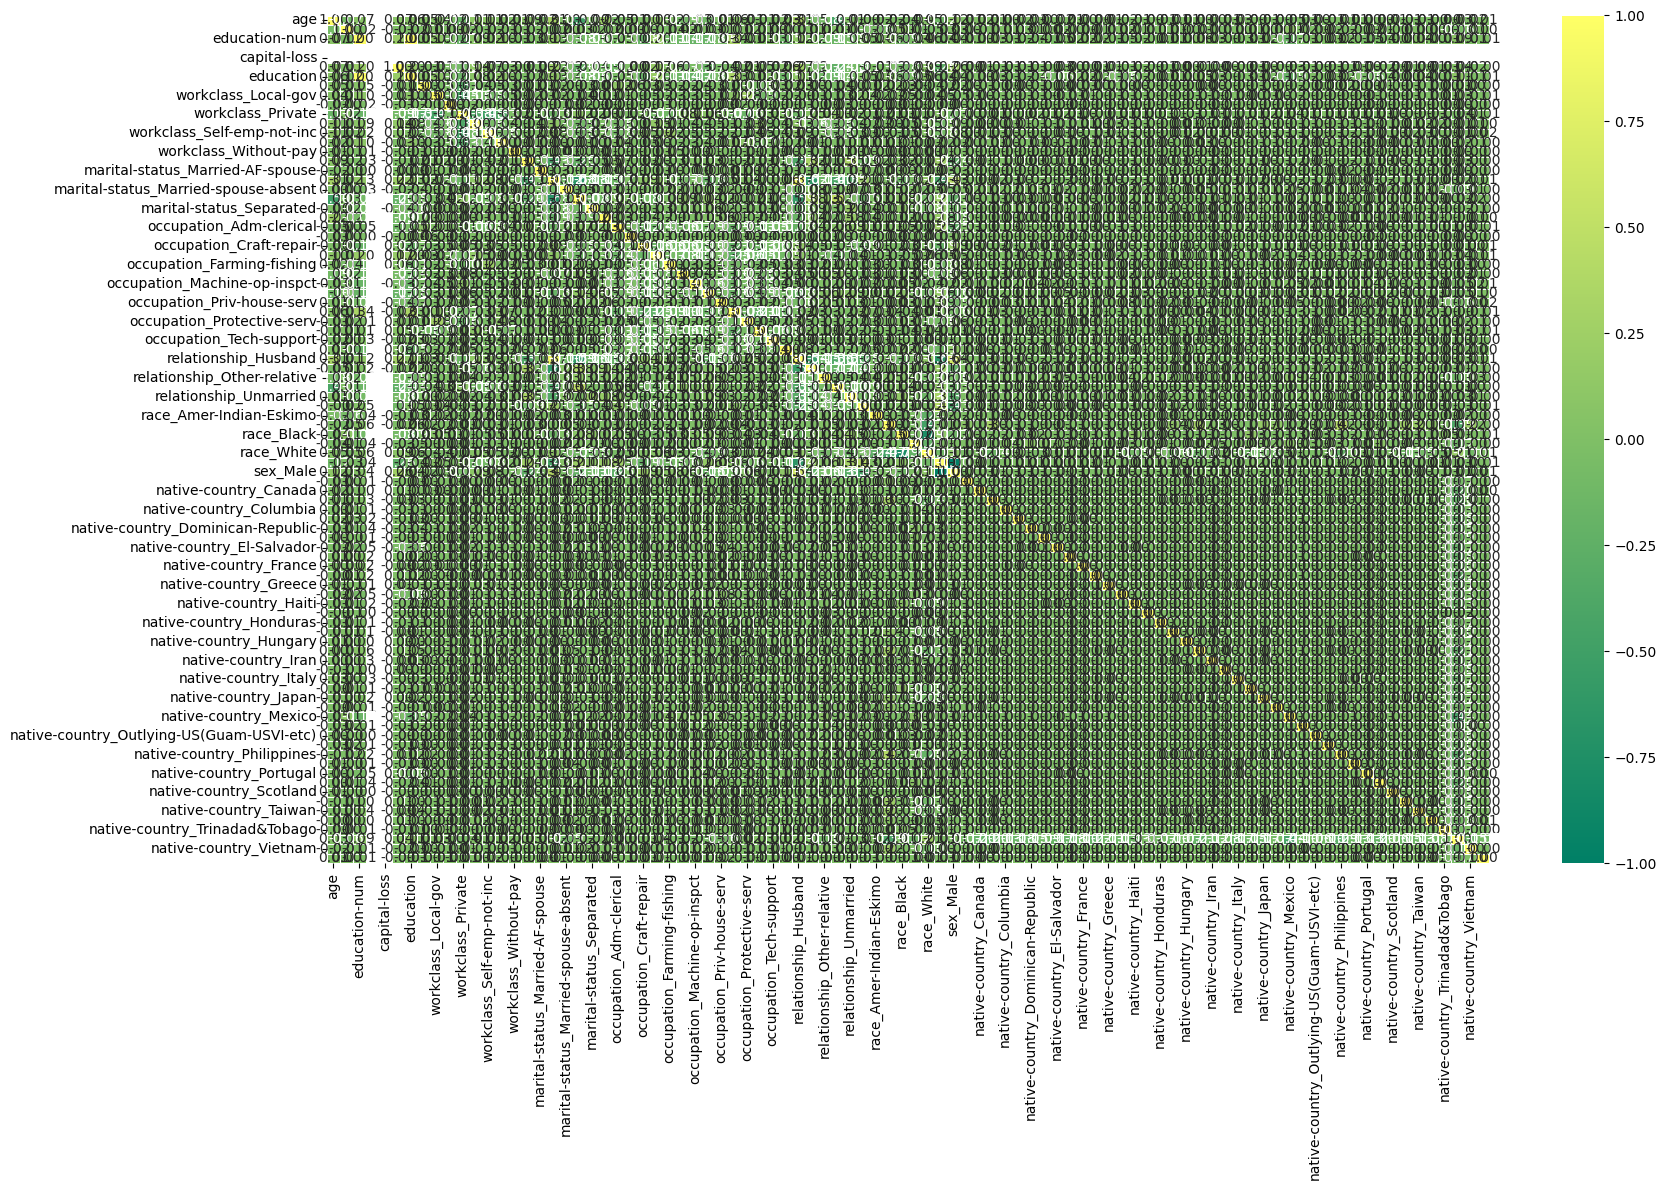

In [215]:
corr = X_train_balanced.corr()
plt.figure(figsize=(18,12))
sns.heatmap(corr,annot=True,cmap='summer',fmt=".2f",linewidth=.5)
plt.tight_layout()
plt.show()

c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


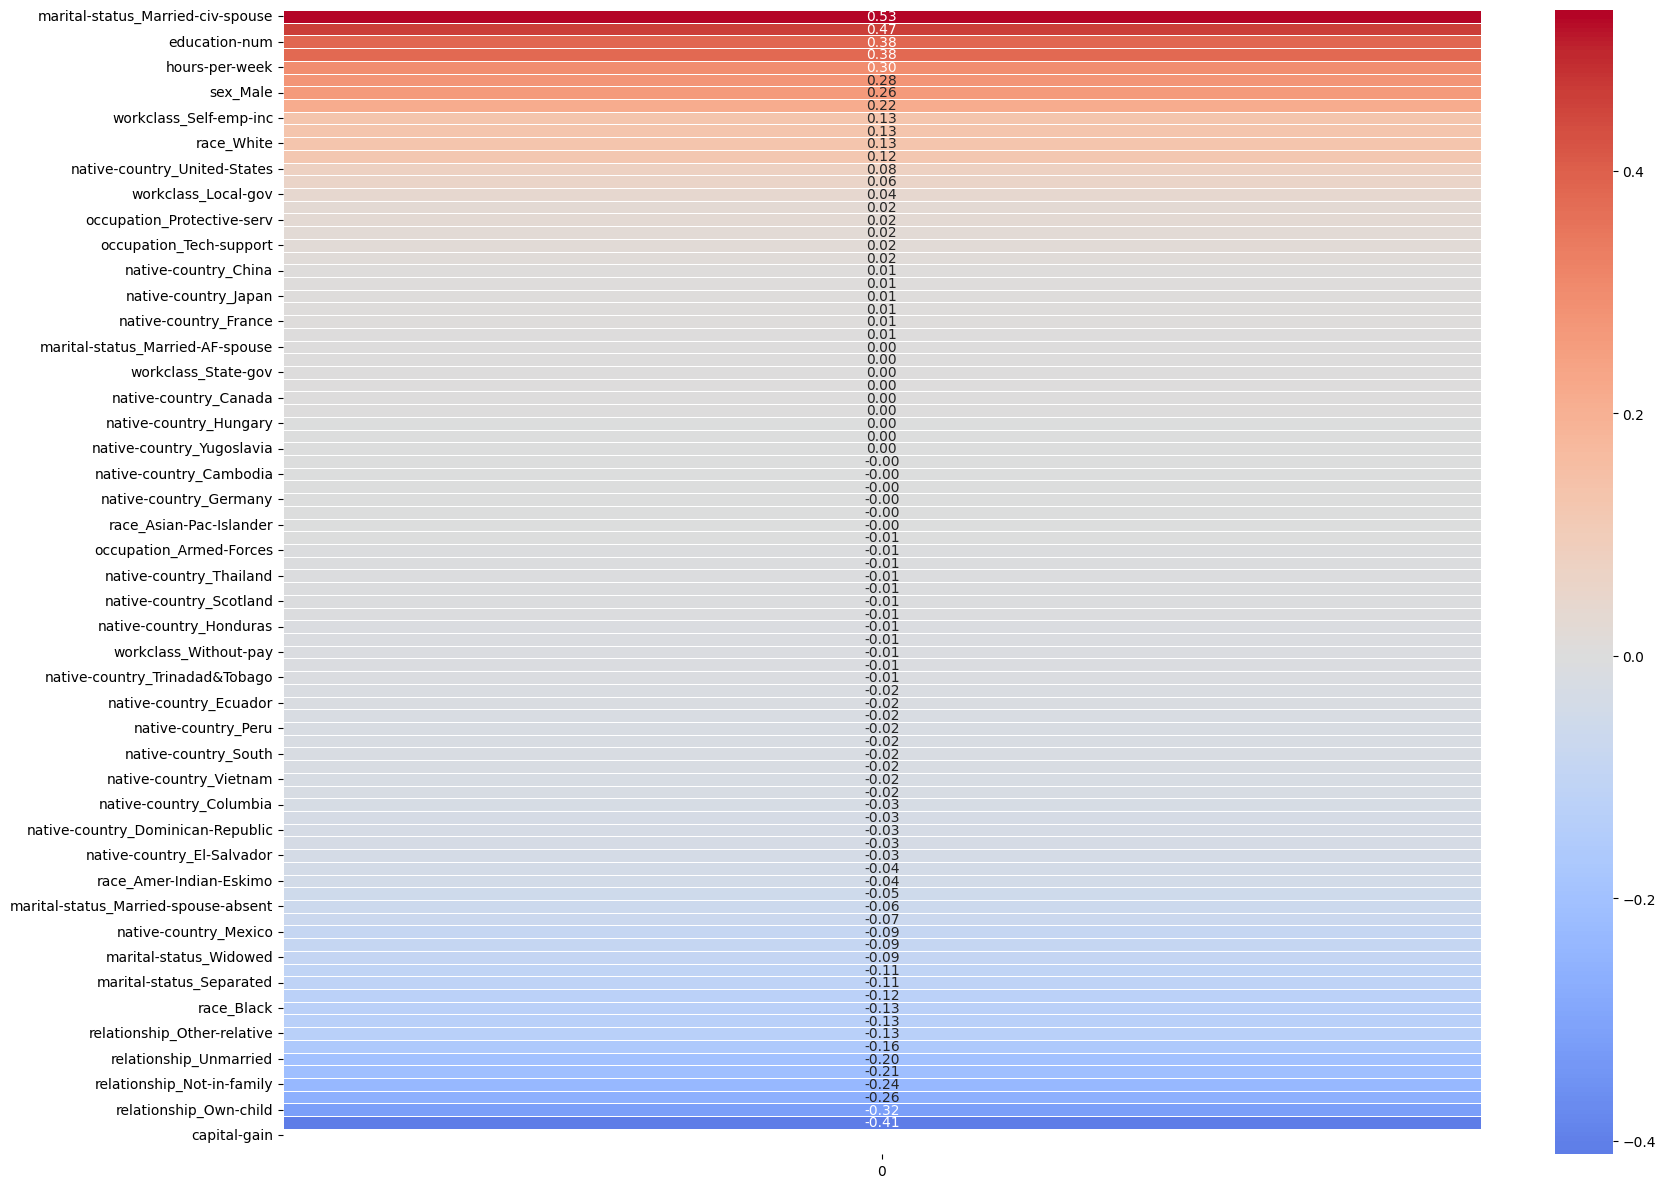

In [216]:
corr_target=X_train_balanced.corrwith(y_train_balanced).sort_values(ascending=False).to_frame()

plt.figure(figsize=(18,12))
sns.heatmap(corr_target,annot=True,cmap='coolwarm',fmt=".2f",linewidth=.5,center=0)#
plt.tight_layout()
plt.show()

In [217]:
adult_df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [218]:
featured_columns = ["marital-status", "education-num", "hours-per-week"]

In [219]:
summary = pd.DataFrame({
    "Column / Area": [
        "Duplicates",
        "workclass",
        "occupation",
        "native-country",
        "Numerical missing values",
        "Categorical missing values",
        "age",
        "hours-per-week",
        "capital-gain",
        "capital-loss",
        "education",
        "Nominal categorical columns",
        "income",
        "Numerical features",
    ],

    "Problem Found": [
        "Duplicate rows",
        "'?' represents missing values",
        "'?' represents missing values",
        "'?' represents missing values",
        "Missing numerical observations",
        "Missing categorical observations",
        "Extreme values/outliers",
        "Extreme values/outliers",
        "Large range/skew",
        "Large range/skew",
        "Ordered categorical variable",
        "No natural numerical order",
        "Binary categorical target",
        "Different scales and ranges"
    ],

    "Action": [
        "Removed duplicates",
        "Converted '?' to NaN and imputed",
        "Converted '?' to NaN and imputed",
        "Converted '?' to NaN and imputed",
        "Median imputation",
        "Most-frequent imputation",
        "Inspected and capped using training IQR limits",
        "Inspected and capped using training IQR limits",
        "Standard scaling / inspected for skew",
        "Standard scaling / inspected for skew",
        "Ordinal encoding",
        "One-hot encoding",
        "Encoded as 0 and 1",
        "StandardScaler",
    ],

    "Reason": [
        "Avoid repeated observations influencing the model",
        "'?' is not a genuine category",
        "'?' is not a genuine category",
        "'?' is not a genuine category",
        "Median is robust to extreme values",
        "Mode preserves the most common category",
        "Preserve rows while reducing extreme influence",
        "Preserve rows while reducing extreme influence",
        "Put numerical features on comparable scales",
        "Put numerical features on comparable scales",
        "Education has a meaningful order",
        "Nominal categories have no meaningful order",
        "Binary target requires class labels",
        "Improves comparability for modelling",
    ]
})

display(summary)

,Column / Area,Problem Found,Action,Reason
0,Duplicates,Duplicate rows,Removed duplicates,Avoid repeated observations influencing the model
1,workclass,'?' represents missing values,Converted '?' to NaN and imputed,'?' is not a genuine category
2,occupation,'?' represents missing values,Converted '?' to NaN and imputed,'?' is not a genuine category
3,native-country,'?' represents missing values,Converted '?' to NaN and imputed,'?' is not a genuine category
4,Numerical missing values,Missing numerical observations,Median imputation,Median is robust to extreme values
5,Categorical missing values,Missing categorical observations,Most-frequent imputation,Mode preserves the most common category
6,age,Extreme values/outliers,Inspected and capped using training IQR limits,Preserve rows while reducing extreme influence
7,hours-per-week,Extreme values/outliers,Inspected and capped using training IQR limits,Preserve rows while reducing extreme influence
8,capital-gain,Large range/skew,Standard scaling / inspected for skew,Put numerical features on comparable scales
9,capital-loss,Large range/skew,Standard scaling / inspected for skew,Put numerical features on comparable scales
